# Week7_ex2 — Distance and overcurrent relays on the 37-bus system (light check)

An extension rather than a textbook reproduction: it reuses the 37-bus design case and sequence networks of Week6_ex2 (Problem 10.64 data, matched to PowerWorld's fault analysis) to see what a distance relay at PEACH138 and non-directional overcurrent relays around the ELM138–LEMON138–TULIP138–PEACH138 ring see for bolted faults. Fault quantities come from the sequence bus impedance matrices with loads and pre-fault voltages included, and the overcurrent trip logic is pandapower's `OCRelay`.

![PowerWorld one-line](Images/Week7_ex2_result_image.png)

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandapower.protection.run_protection import calculate_protection_times
from case37 import S_BASE, LINES, build_case, solve_pw
from fault37 import BUSES, POS, build_sc_case
from relay37 import (LINE_Z1, LINE_Z0, fault_case, branch_current, relay_view, mho_zone, add_oc_relays)

IMG = Path("Images")
IMG.mkdir(exist_ok=True)
NAME = {b: n for b, n, _ in BUSES}
Z_BASE = 138.0 ** 2 / S_BASE                     # ohm, every bus in this study is 138 kV
I_BASE = S_BASE / (math.sqrt(3) * 138.0)         # kA

# 1. Distance relay at PEACH138 (bus 41) on the line to ELM138 (bus 29). The case lists the line
#    from 29 to 41, so a fault at distance d from the relay sits at x = 1 - d of the line
LINE = (29, 41, "1")
RELAY_BUS = 41
Z1L, B1L = LINE_Z1[LINE]
Z0L, B0L = LINE_Z0[LINE]
K0 = (Z0L - Z1L) / (3 * Z1L)                     # residual compensation of the ground element
ADJ = [(32, 29, "1"), (56, 29, "1")]             # lines leaving the remote bus (ELM138 - LEMON138, - PLUM138)
Z_ADJ_LONG = max((LINE_Z1[a][0] for a in ADJ), key=abs)

# 2. Typical stepped-distance settings: zone 1 underreaches the line, zone 2 overreaches it by 20%,
#    zone 3 covers the line plus 120% of the longest adjacent line; mho circles on the line angle.
#    The delays are common practice, not taken from the case
ZONES = [("Z1", 0.8 * Z1L), ("Z2", 1.2 * Z1L), ("Z3", Z1L + 1.2 * Z_ADJ_LONG)]
DELAY = {"Z1": 0.0, "Z2": 0.3, "Z3": 1.0, "none": np.nan}
net = solve_pw(build_case(), numba=False)
pd.DataFrame([{"Zone": z, "Reach |Z| [pu]": abs(r), "Reach |Z| [ohm]": abs(r) * Z_BASE,
               "Angle [deg]": np.degrees(np.angle(r)), "Delay [s]": DELAY[z]} for z, r in ZONES]
             + [{"Zone": "k0 = (Z0L - Z1L) / 3Z1L", "Reach |Z| [pu]": abs(K0), "Reach |Z| [ohm]": np.nan,
                 "Angle [deg]": np.degrees(np.angle(K0)), "Delay [s]": np.nan}]).round(4)

,Zone,Reach |Z| [pu],Reach |Z| [ohm],Angle [deg],Delay [s]
0,Z1,0.1018,19.3911,81.5605,0.0
1,Z2,0.1527,29.0866,81.5605,0.3
2,Z3,0.1965,37.4288,80.9130,1.0
3,k0 = (Z0L - Z1L) / 3Z1L,0.5000,NaN,-0.0000,NaN


In [2]:
# 3. Hand check: with the faulted line's own charging removed, the phase element (three-phase fault)
#    and the compensated ground element (phase-a fault) must both read exactly d * Z1L, whatever the
#    infeed from the remote end and the pre-fault load, because the fault point is at zero volts
rows = []
for kind, key in (("3ph", "z_phase"), ("slg", "z_ground_comp")):
    for d in (0.1, 0.3, 0.5, 0.7, 0.9):
        fault = fault_case(net, (LINE, 1 - d), kind, charging=False)
        i012 = branch_current(fault[0], RELAY_BUS, LINE, fault, charging=False)
        z = relay_view(fault[0][:, POS[RELAY_BUS]], i012, K0)[key]
        for part, val, ref in (("R", z.real, (d * Z1L).real), ("X", z.imag, (d * Z1L).imag)):
            rows.append((f"{kind} d={d} {part} [pu]", val, ref))
df = pd.DataFrame(rows, columns=["Quantity", "Relay", "d * Z1L"])
df["Abs diff"] = (df.Relay - df["d * Z1L"]).abs()
assert (df["Abs diff"] < 1e-9).all()
df.round(6)

,Quantity,Relay,d * Z1L,Abs diff
0,3ph d=0.1 R [pu],0.001868,0.001868,0.0
1,3ph d=0.1 X [pu],0.012590,0.012590,0.0
2,3ph d=0.3 R [pu],0.005604,0.005604,0.0
3,3ph d=0.3 X [pu],0.037770,0.037770,0.0
4,3ph d=0.5 R [pu],0.009340,0.009340,0.0
5,3ph d=0.5 X [pu],0.062950,0.062950,0.0
6,3ph d=0.7 R [pu],0.013076,0.013076,0.0
7,3ph d=0.7 X [pu],0.088130,0.088130,0.0
8,3ph d=0.9 R [pu],0.016812,0.016812,0.0
9,3ph d=0.9 X [pu],0.113310,0.113310,0.0


In [3]:
# 4. Faults along the protected line with charging back in. The ground element without k0 sees
#    Va / Ia, which is too large by roughly (1 + k0 * 3I0 / Ia), so it underreaches
rows = []
for kind in ("3ph", "slg"):
    for d in (0.05, 0.25, 0.5, 0.75, 0.85, 0.95, 1.0):
        where = 29 if d == 1.0 else (LINE, 1 - d)
        fault = fault_case(net, where, kind)
        view = relay_view(fault[0][:, POS[RELAY_BUS]], branch_current(fault[0], RELAY_BUS, LINE, fault), K0)
        z = view["z_phase"] if kind == "3ph" else view["z_ground_comp"]
        row = {"Fault": kind, "Distance d": d, "|Z| seen [pu]": abs(z), "|Z| / |d Z1L|": abs(z) / abs(d * Z1L),
               "Zone": mho_zone(z, ZONES), "Trip delay [s]": DELAY[mho_zone(z, ZONES)]}
        if kind == "slg":
            row["Zone without k0"] = mho_zone(view["z_ground_raw"], ZONES)
        rows.append(row)
pd.DataFrame(rows).round(4)

,Fault,Distance d,|Z| seen [pu],|Z| / |d Z1L|,Zone,Trip delay [s],Zone without k0
0,3ph,0.05,0.0064,1.0000,Z1,0.0,NaN
1,3ph,0.25,0.0318,1.0001,Z1,0.0,NaN
2,3ph,0.50,0.0637,1.0006,Z1,0.0,NaN
3,3ph,0.75,0.0956,1.0013,Z1,0.0,NaN
4,3ph,0.85,0.1084,1.0016,Z2,0.3,NaN
5,3ph,0.95,0.1212,1.0020,Z2,0.3,NaN
6,3ph,1.00,0.1276,1.0022,Z2,0.3,NaN
7,slg,0.05,0.0064,0.9998,Z1,0.0,Z1
8,slg,0.25,0.0318,0.9991,Z1,0.0,Z1
9,slg,0.50,0.0635,0.9978,Z1,0.0,Z1


In [4]:
# 5. Faults on the lines beyond ELM138. ELM345 feeds bus 29 through two transformers, so the current
#    into the faulted adjacent line is several times the relay current and the relay sees
#    Z1L + K * y * Z_adj with K = I_adjacent / I_relay > 1: the zones reach far less than they are set
rows = []
for adj in ADJ:
    z_adj = LINE_Z1[adj][0]
    for kind in ("3ph", "slg"):
        for y in (0.05, 0.1, 0.25, 0.5, 0.75):
            fault = fault_case(net, (adj, 1 - y), kind)       # y measured from ELM138 (bus 29)
            i_rel = branch_current(fault[0], RELAY_BUS, LINE, fault)
            i_adj = branch_current(fault[0], 29, adj, fault)
            view = relay_view(fault[0][:, POS[RELAY_BUS]], i_rel, K0)
            z = view["z_phase"] if kind == "3ph" else view["z_ground_comp"]
            rows.append({"Adjacent line": f"{NAME[29]}-{NAME[adj[0]]}", "Fault": kind, "y from ELM138": y,
                         "|I_adj / I_relay|": abs(i_adj[1] / i_rel[1]), "|Z| seen [pu]": abs(z),
                         "Angle seen [deg]": np.degrees(np.angle(z)), "|Z1L + y Z_adj| [pu]": abs(Z1L + y * z_adj),
                         "Zone seen": mho_zone(z, ZONES), "Zone without infeed": mho_zone(Z1L + y * z_adj, ZONES)})
infeed = pd.DataFrame(rows)
infeed.round(4)

,Adjacent line,Fault,y from ELM138,|I_adj / I_relay|,|Z| seen [pu],Angle seen [deg],|Z1L + y Z_adj| [pu],Zone seen,Zone without infeed
0,ELM138-LEMON138,3ph,0.05,7.3033,0.1486,82.4676,0.1302,Z2,Z2
1,ELM138-LEMON138,3ph,0.10,7.6309,0.1714,83.5526,0.1330,Z3,Z2
2,ELM138-LEMON138,3ph,0.25,8.9108,0.2549,87.8974,0.1417,none,Z2
3,ELM138-LEMON138,3ph,0.50,12.9953,0.4930,101.9102,0.1561,none,Z3
4,ELM138-LEMON138,3ph,0.75,21.3822,0.9749,146.5463,0.1706,none,Z3
5,ELM138-LEMON138,slg,0.05,2.9800,0.1375,84.4965,0.1302,Z2,Z2
6,ELM138-LEMON138,slg,0.10,2.9030,0.1496,87.6707,0.1330,Z2,Z2
7,ELM138-LEMON138,slg,0.25,2.6874,0.1888,97.4353,0.1417,none,Z2
8,ELM138-LEMON138,slg,0.50,2.3749,0.2603,116.7312,0.1561,none,Z3
9,ELM138-LEMON138,slg,0.75,2.1112,0.3135,142.7095,0.1706,none,Z3


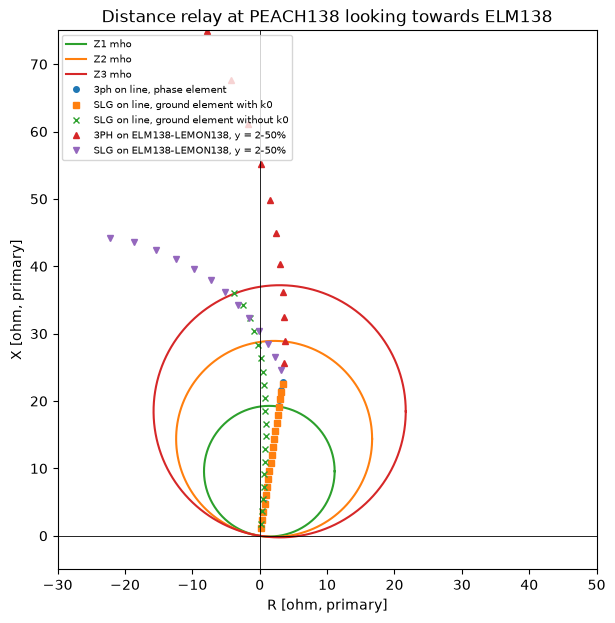

In [5]:
# 6. R-X picture: mho zones, faults on the protected line, and faults on ELM138-LEMON138
fig, ax = plt.subplots(figsize=(7, 7))
th = np.linspace(0, 2 * np.pi, 300)
for (name, reach), color in zip(ZONES, ("tab:green", "tab:orange", "tab:red")):
    c = reach / 2 * Z_BASE
    ax.plot(c.real + abs(c) * np.cos(th), c.imag + abs(c) * np.sin(th), color=color, label=f"{name} mho")
ds = np.linspace(0.05, 0.95, 19)
for kind, key, marker, label in (("3ph", "z_phase", "o", "3ph on line, phase element"),
                                 ("slg", "z_ground_comp", "s", "SLG on line, ground element with k0"),
                                 ("slg", "z_ground_raw", "x", "SLG on line, ground element without k0")):
    pts = []
    for d in ds:
        fault = fault_case(net, (LINE, 1 - d), kind)
        pts.append(relay_view(fault[0][:, POS[RELAY_BUS]], branch_current(fault[0], RELAY_BUS, LINE, fault), K0)[key])
    pts = np.array(pts) * Z_BASE
    ax.plot(pts.real, pts.imag, marker, ms=4, label=label)
for kind, marker in (("3ph", "^"), ("slg", "v")):
    pts = []
    for y in np.linspace(0.02, 0.5, 13):
        fault = fault_case(net, (ADJ[0], 1 - y), kind)
        view = relay_view(fault[0][:, POS[RELAY_BUS]], branch_current(fault[0], RELAY_BUS, LINE, fault), K0)
        pts.append(view["z_phase"] if kind == "3ph" else view["z_ground_comp"])
    pts = np.array(pts) * Z_BASE
    ax.plot(pts.real, pts.imag, marker, ms=4, label=f"{kind.upper()} on ELM138-LEMON138, y = 2-50%")
ax.set_xlim(-30, 50)
ax.set_ylim(-5, 75)
ax.set_aspect("equal")
ax.axhline(0, color="k", lw=0.6)
ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("R [ohm, primary]")
ax.set_ylabel("X [ohm, primary]")
ax.set_title("Distance relay at PEACH138 looking towards ELM138")
ax.legend(fontsize=7, loc="upper left")
fig.savefig(IMG / "Week7_ex2_distance_rx_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# 7. Overcurrent relays at both ends of the four ring lines, all standard inverse (IEC: k = 0.14,
#    alpha = 0.02) with TMS = 0.1 and pickup = 1.2 x the line's thermal current, the default rule
#    pandapower uses for IDMT. Nothing is graded: the point is what the relays see, not a setting study
RING = [(29, 41, "1"), (30, 41, "1"), (30, 32, "1"), (32, 29, "1")]
RELAYS = [(bus, line) for line in RING for bus in line[:2]]
RATING = {(f, t, c): lim for f, t, c, r, x, b, lim in LINES}
PICKUP = [1.2 * RATING[line] / (math.sqrt(3) * 138.0) for _, line in RELAYS]
TMS, K_SI, ALPHA_SI = 0.1, 0.14, 0.02
net_sc = add_oc_relays(build_sc_case(banks=False), RELAYS, PICKUP, TMS)
pd.DataFrame({"Switch": net_sc.switch.index,
              "Relay": [f"{NAME[b]} on {NAME[l[0]]}-{NAME[l[1]]}" for b, l in RELAYS],
              "Forward = into the line from": [NAME[b] for b, _ in RELAYS],
              "Pickup [kA]": PICKUP, "TMS": TMS}).round(4)

,Switch,Relay,Forward = into the line from,Pickup [kA],TMS
0,0,ELM138 on ELM138-PEACH138,ELM138,0.9589,0.1
1,1,PEACH138 on ELM138-PEACH138,PEACH138,0.9589,0.1
2,2,TULIP138 on TULIP138-PEACH138,TULIP138,0.9589,0.1
3,3,PEACH138 on TULIP138-PEACH138,PEACH138,0.9589,0.1
4,4,TULIP138 on TULIP138-LEMON138,TULIP138,0.9589,0.1
5,5,LEMON138 on TULIP138-LEMON138,LEMON138,0.9589,0.1
6,6,LEMON138 on LEMON138-ELM138,LEMON138,0.9589,0.1
7,7,ELM138 on LEMON138-ELM138,ELM138,0.9589,0.1


In [7]:
# 8. Three-phase faults at the middle of each ring line. Currents from the sequence Zbus go into
#    res_switch_sc and pandapower's OCRelay turns them into trip times, checked against the IEC formula
#    t = TMS * k / ((I / I_s)^alpha - 1). Direction: the relay looks forward when the fault sits in
#    front of it, i.e. the apparent impedance V1 / I1 has positive reactance
def ring_fault(line):
    fault = fault_case(net, (line, 0.5), "3ph")
    out = []
    for (bus, rl), pick in zip(RELAYS, PICKUP):
        i012 = branch_current(fault[0], bus, rl, fault)
        i_ka = abs(i012[1]) * I_BASE
        z = fault[0][1, POS[bus]] / i012[1]
        out.append({"Fault on": f"{NAME[line[0]]}-{NAME[line[1]]}",
                    "Relay": f"{NAME[bus]} on {NAME[rl[0]]}-{NAME[rl[1]]}", "Own line": rl == line,
                    "Direction": "forward" if z.imag > 0 else "reverse", "I [kA]": i_ka,
                    "IEC formula [s]": TMS * K_SI / ((i_ka / pick) ** ALPHA_SI - 1) if i_ka > pick else np.inf})
    df = pd.DataFrame(out)
    net_sc["res_switch_sc"] = pd.DataFrame({"ikss_ka": df["I [kA]"].to_numpy()}, index=net_sc.switch.index)
    df["pandapower OCRelay [s]"] = calculate_protection_times(net_sc, scenario="sc").trip_melt_time_s.to_numpy()
    return df


trips = pd.concat([ring_fault(line) for line in RING], ignore_index=True)
finite = np.isfinite(trips["IEC formula [s]"])
assert (finite == np.isfinite(trips["pandapower OCRelay [s]"])).all()
assert np.allclose(trips.loc[finite, "IEC formula [s]"], trips.loc[finite, "pandapower OCRelay [s]"], rtol=0, atol=1e-12)
trips.round(4)

,Fault on,Relay,Own line,Direction,I [kA],IEC formula [s],pandapower OCRelay [s]
0,ELM138-PEACH138,ELM138 on ELM138-PEACH138,True,forward,3.7041,0.5110,0.5110
1,ELM138-PEACH138,PEACH138 on ELM138-PEACH138,True,forward,3.3178,0.5570,0.5570
2,ELM138-PEACH138,TULIP138 on TULIP138-PEACH138,False,forward,0.4753,inf,inf
3,ELM138-PEACH138,PEACH138 on TULIP138-PEACH138,False,reverse,0.4776,inf,inf
4,ELM138-PEACH138,TULIP138 on TULIP138-LEMON138,False,reverse,0.5172,inf,inf
5,ELM138-PEACH138,LEMON138 on TULIP138-LEMON138,False,forward,0.5164,inf,inf
6,ELM138-PEACH138,LEMON138 on LEMON138-ELM138,False,forward,0.2913,inf,inf
7,ELM138-PEACH138,ELM138 on LEMON138-ELM138,False,reverse,0.2922,inf,inf
8,TULIP138-PEACH138,ELM138 on ELM138-PEACH138,False,forward,0.9819,29.4999,29.4999
9,TULIP138-PEACH138,PEACH138 on ELM138-PEACH138,False,reverse,0.9880,23.3867,23.3867


In [8]:
# 9. Selectivity: the faulted line's two relays should trip first and every relay on a healthy line
#    should wait at least a coordination margin (0.3 s is a common figure) after the slower of them.
#    Non-directional relays see the through-current flowing around the ring in either direction
MARGIN = 0.3
rows = []
for fault_on, df in trips.groupby("Fault on", sort=False):
    own = df[df["Own line"]]
    clear = own["pandapower OCRelay [s]"].max()
    healthy = df[~df["Own line"]]
    fastest = healthy.loc[healthy["pandapower OCRelay [s]"].idxmin()]
    fwd = healthy[healthy.Direction == "forward"]
    fastest_fwd = fwd.loc[fwd["pandapower OCRelay [s]"].idxmin()]
    picks_up = np.isfinite(fastest["pandapower OCRelay [s]"])
    rows.append({"Fault on": fault_on, "Faulted line cleared [s]": clear,
                 "Fastest healthy-line relay": fastest.Relay if picks_up else "none picks up",
                 "Its direction": fastest.Direction if picks_up else "-",
                 "Its time [s]": fastest["pandapower OCRelay [s]"],
                 "Margin, non-directional [s]": fastest["pandapower OCRelay [s]"] - clear,
                 "Margin, forward-only relays [s]": fastest_fwd["pandapower OCRelay [s]"] - clear})
sel = pd.DataFrame(rows)
sel["Selective (non-directional)"] = sel["Margin, non-directional [s]"] >= MARGIN
sel["Selective (directional)"] = sel["Margin, forward-only relays [s]"] >= MARGIN
sel.round(4)

,Fault on,Faulted line cleared [s],Fastest healthy-line relay,Its direction,Its time [s],"Margin, non-directional [s]","Margin, forward-only relays [s]",Selective (non-directional),Selective (directional)
0,ELM138-PEACH138,0.5570,none picks up,-,inf,inf,inf,True,True
1,TULIP138-PEACH138,0.5841,TULIP138 on TULIP138-LEMON138,reverse,0.5831,-0.0011,-0.0010,False,False
2,TULIP138-LEMON138,0.5267,TULIP138 on TULIP138-PEACH138,reverse,0.5264,-0.0003,-0.0001,False,False
3,LEMON138-ELM138,0.5864,TULIP138 on TULIP138-PEACH138,reverse,0.8694,0.2830,0.2840,False,False


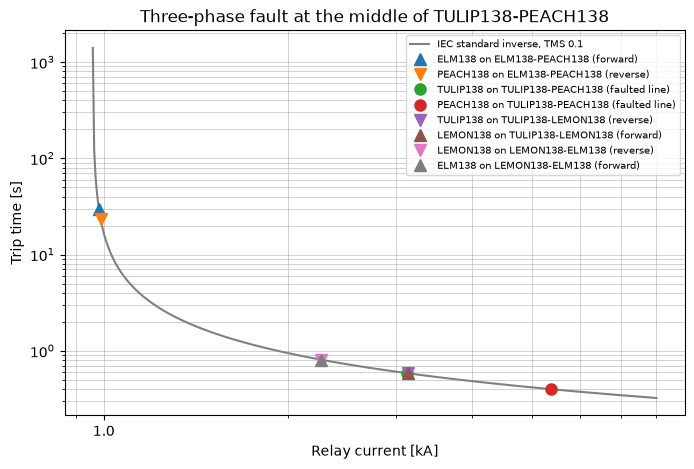

In [9]:
# 10. Time-current picture for the fault on TULIP138-PEACH138: the curve is the same for every relay
#     (same rating, pickup and TMS), so the trip order is simply the order of the currents
df = trips[trips["Fault on"] == f"{NAME[30]}-{NAME[41]}"]
i = np.logspace(np.log10(PICKUP[0] * 1.0005), np.log10(8), 400)
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(i, TMS * K_SI / ((i / PICKUP[0]) ** ALPHA_SI - 1), color="gray", label="IEC standard inverse, TMS 0.1")
for _, r in df.iterrows():
    style = "o" if r["Own line"] else ("^" if r.Direction == "forward" else "v")
    if np.isfinite(r["pandapower OCRelay [s]"]):
        ax.loglog(r["I [kA]"], r["pandapower OCRelay [s]"], style, ms=8,
                  label=f"{r.Relay} ({'faulted line' if r['Own line'] else r.Direction})")
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Relay current [kA]")
ax.set_ylabel("Trip time [s]")
ax.set_title("Three-phase fault at the middle of TULIP138-PEACH138")
ax.grid(True, which="both", lw=0.4)
ax.legend(fontsize=7)
fig.savefig(IMG / "Week7_ex2_overcurrent_ring_trip_times.png", dpi=150, bbox_inches="tight")
plt.show()